In [103]:
import soccerdata as sd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import matplotlib.image as mping
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

In [2]:
season = ["2016/2017","2017/2018", "2018/2019", "2019/2020", "2020/2021", "2021/2022", "2022/2023", "2023/2024", "2024/2025", "2025/2026"]

#hist = sd.MatchHistory(leagues="ENG-Premier League", seasons=season)

In [3]:
#games = hist.read_games()

In [4]:
#games.reset_index(inplace=True)

#games = games[["season", "date", "home_team", "away_team", "home_goals", "away_goals"]]

In [5]:
understat = sd.Understat(seasons=season, leagues="ENG-Premier League")
shots = understat.read_shot_events()

[10/15/26 11:19:51] INFO     Saving cached data to C:\Users\elvin\soccerdata\data\Understat          ]8;id=8182057;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=8182058;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_common.py#250\250]8;;\

[2026-10-15 11:19:51] INFO     TLSLibrary:_load_library:397 - Successfully loaded TLS library: C:\Users\elvin\anaconda3\envs\myenv\Lib\site-packages\tls_requests\bin\tls-client-xgo-1.13.1-windows-amd64.dll


                    INFO     Successfully loaded TLS library:                                      ]8;id=8182065;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\tls_requests\models\libraries.py\libraries.py]8;;\:]8;id=8182066;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\tls_requests\models\libraries.py#397\397]8;;\
                             C:\Users\elvin\anaconda3\envs\myenv\Lib\site-packages\tls_requests\bi                 
                             n\tls-client-xgo-1.13.1-windows-amd64.dll                                             

In [6]:
schedule = understat.read_schedule().reset_index()

In [7]:
goals = shots.reset_index()
goals = goals[goals['result'].isin(["Goal", "Own Goal"])]
goals = goals.merge(schedule[['game_id','home_team', 'away_team']], on="game_id")

In [8]:
og = goals['result'] == 'Own Goal'
goals['scoring_team'] = np.where(~og, goals['team'],
             np.where(goals['team']== goals['home_team'], goals['away_team'], goals['home_team']))


opener = (goals.sort_values(['game_id','minute',"shot_id"]).groupby('game_id').first()[["scoring_team",'minute']]
          .rename(columns={'scoring_team':'first_scorer','minute':"first_goal_min"}))

matches = schedule.merge(opener, on="game_id")
matches['winner'] = np.select([matches['home_goals']>matches['away_goals'], matches['home_goals']<matches['away_goals']],
          [matches['home_team'], matches['away_team']], default=None)

comebacks = matches[matches['winner'].notna() & (matches['first_scorer'] != matches['winner'])]

In [14]:
cb = comebacks[['season','date','home_team','away_team','home_goals','away_goals','first_scorer','winner','first_goal_min']].sort_values(['season','date'])

In [10]:
comebacks.groupby(['season','winner']).size().unstack(fill_value=0).sort_index()

winner,Arsenal,Aston Villa,Bournemouth,Brentford,Brighton,Burnley,Cardiff,Chelsea,Crystal Palace,Everton,...,Sheffield United,Southampton,Stoke,Sunderland,Swansea,Tottenham,Watford,West Bromwich Albion,West Ham,Wolverhampton Wanderers
season,,,,,,,,,,,,,,,,,,,,,
1617,2,0,2,0,0,0,0,4,3,3,...,0,3,0,1,2,4,2,3,2,0
1718,3,0,5,0,0,2,0,2,4,3,...,0,1,2,0,2,3,2,0,1,0
1819,2,0,1,0,1,3,3,2,1,0,...,0,1,0,0,0,3,2,0,3,3
1920,4,2,1,0,1,1,0,2,2,1,...,2,3,0,0,0,4,2,0,1,4
2021,3,2,0,0,1,1,0,3,2,1,...,1,3,0,0,0,4,0,1,4,4
2122,1,1,0,4,2,1,0,2,1,4,...,0,1,0,0,0,4,1,0,4,1
2223,5,1,4,2,2,0,0,2,7,1,...,0,3,0,0,0,4,0,0,2,2
2324,2,4,3,1,3,0,0,3,2,0,...,0,0,0,0,0,7,0,0,5,3
2425,3,4,3,5,5,0,0,4,2,2,...,0,0,0,0,0,3,0,0,0,2


In [11]:
comebacks.groupby('season')['winner'].count()

season
1617    44
1718    43
1819    41
1920    45
2021    56
2122    43
2223    55
2324    54
2425    59
2526    46
Name: winner, dtype: int64

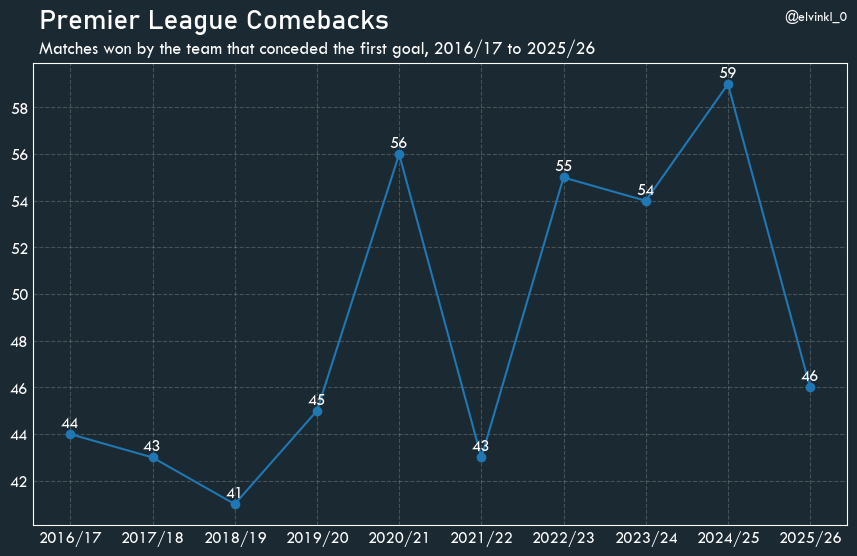

In [12]:
fig, ax = plt.subplots(figsize=(10.5,6))
fig.patch.set_facecolor('#1b2932')
ax.set_facecolor('#1b2932')

cb_per_season = comebacks.groupby('season')['winner'].count().reset_index()
cb_per_season['season'] = '20' + cb_per_season['season'].str[:2] + '/' + cb_per_season['season'].str[2:]
ax.plot(cb_per_season['season'], cb_per_season['winner'], marker='o', color='#1f77b4')

for season, count in zip(cb_per_season['season'], cb_per_season['winner']):
    ax.annotate(str(count), xy=(season, count), xytext=(0, 5), textcoords='offset points', ha='center', color='white', fontfamily='Tw Cen MT', fontsize=12)

#ax.set_xlabel('Season',color='white', fontfamily='Tw Cen MT', fontsize=15)
#ax.set_ylabel('Number of Comebacks', color='white', fontfamily='Tw Cen MT', fontsize=15)
#ax.set_title('Premier League Comebacks', color='white',fontfamily='Bahnschrift', fontsize=30)
fig.text(0.13, 0.97, "Premier League Comebacks", color='white', fontfamily='Bahnschrift', fontsize=20, ha='left', va='top')
fig.text(0.13, 0.92, "Matches won by the team that conceded the first goal, 2016/17 to 2025/26", color='white', fontfamily='Tw Cen MT', fontsize=13, ha='left', va='top')
fig.text(0.9, 0.97, "@elvinkl_0", color='white', fontfamily='Tw Cen MT', fontsize=10, ha='right', va='top')

ax.tick_params(axis='y', colors='white', length=0, labelsize=12, labelfontfamily='Tw Cen MT')
ax.tick_params(axis='x', colors='white', length=0, labelsize=12, labelfontfamily='Tw Cen MT')

ax.yaxis.set_major_locator(MultipleLocator(2))

for spine in ax.spines.values():
    spine.set_color('white')
ax.grid(axis='y',linestyle='--',alpha=0.3)
ax.grid(axis='x',linestyle='--',alpha=0.3)
plt.show()


## Comebacks for each Prem team

In [92]:
team_cb = cb.groupby(['season','winner']).size().unstack(fill_value=0).sort_index()

in_league = (pd.concat([schedule[['season','home_team']].rename(columns={'home_team':'team'}),
                       schedule[['season','away_team']].rename(columns={'away_team':'team'})]).drop_duplicates()
                       .assign(played=True)
                       .pivot(index='season',columns='team',values='played')
                       .reindex(index=team_cb.index, columns=team_cb.columns)
                       .fillna(False)
                       .astype(bool))

team_cb = team_cb.where(in_league)
team_cb.index = team_cb.index.str[:2]+"/"+team_cb.index.str[2:]
team_cb = team_cb.loc[:,team_cb.isnull().sum()<=3]
teams = team_cb.columns



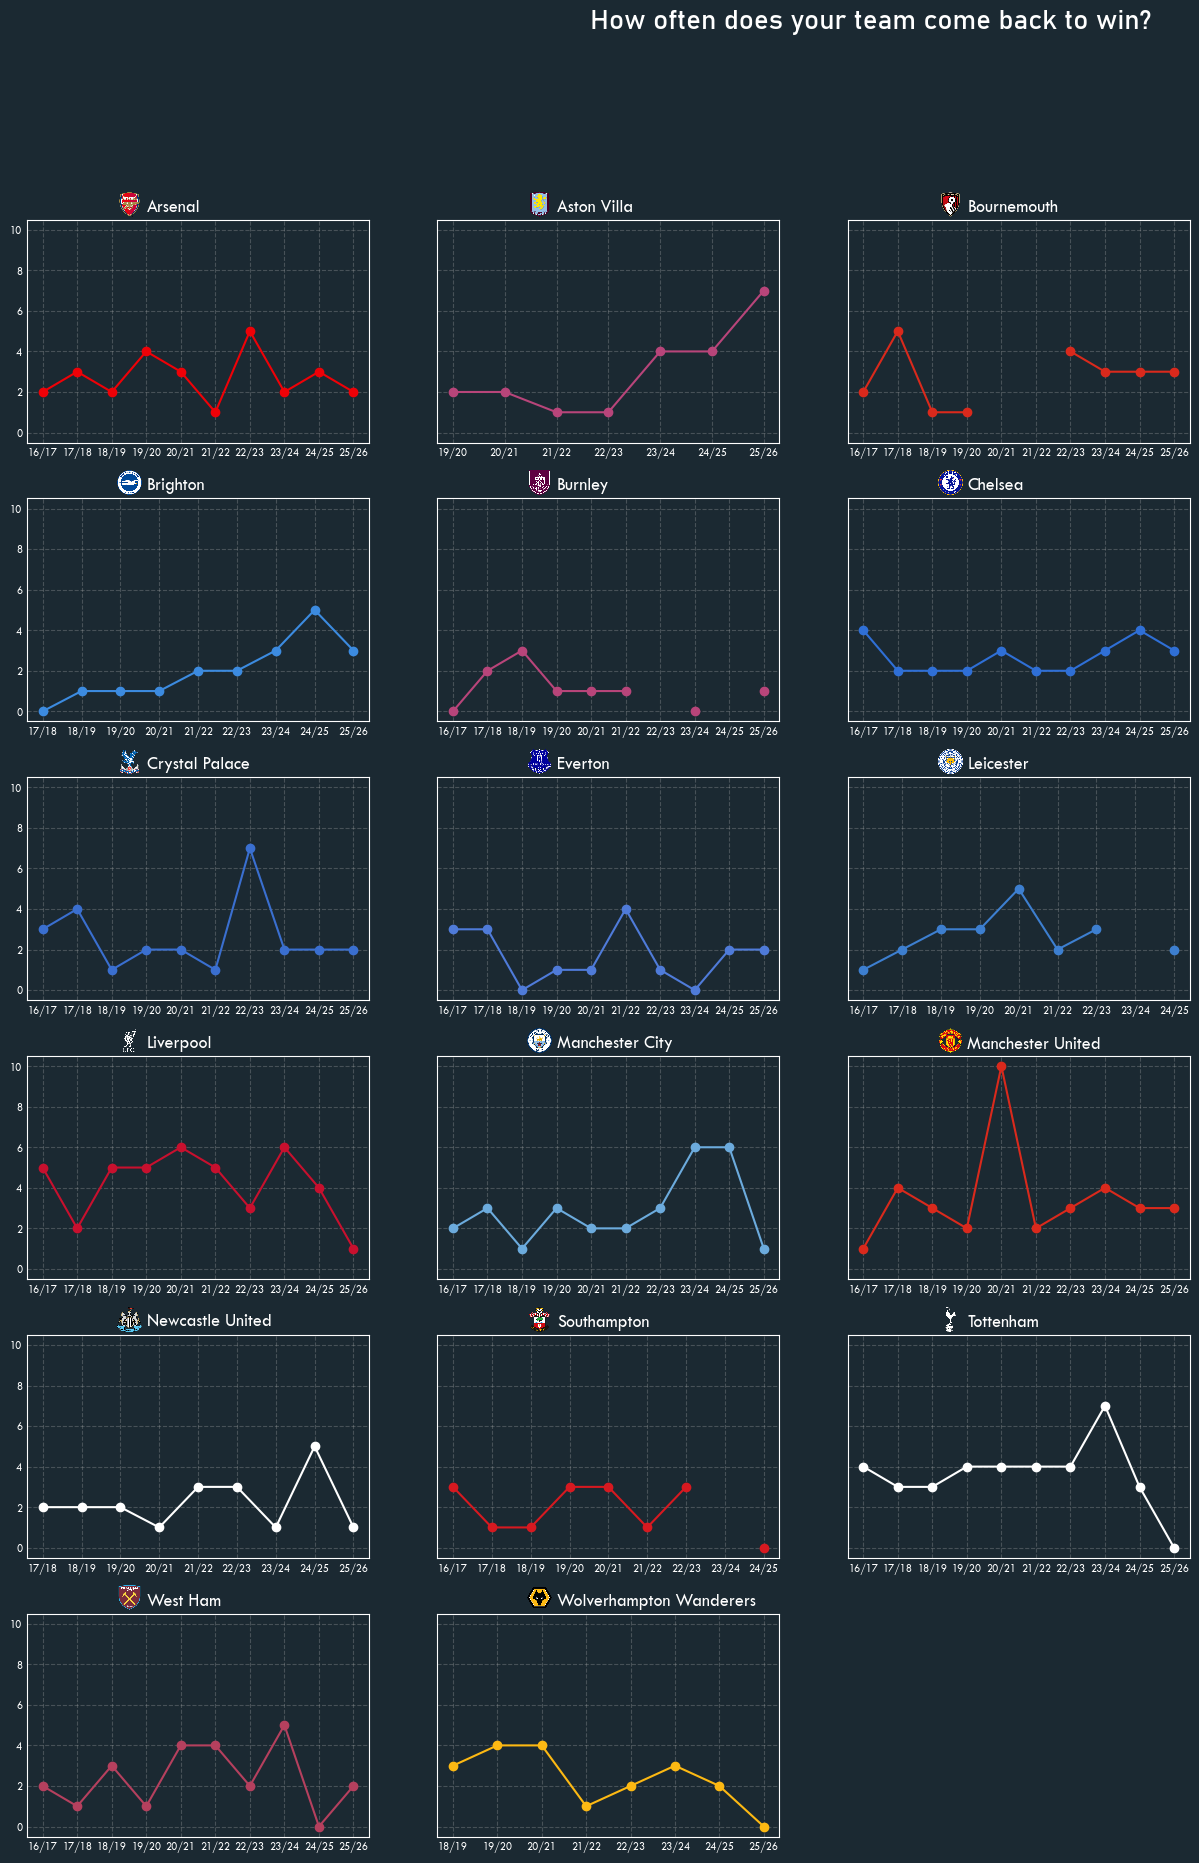

In [133]:
ncols = 3
nrows = (len(teams) + ncols - 1) // ncols

club_colors = {
    'Arsenal': '#EF0107', 'Aston Villa': '#B8457A', 'Bournemouth': '#DA291C', 'Brentford': '#E30613',
    'Brighton': '#3C8BE0', 'Burnley': '#B8457A', 'Cardiff': '#0070B5', 'Chelsea': '#2F6FD6',
    'Crystal Palace': '#3A6FD0', 'Everton': '#4F7BD9', 'Fulham': '#FFFFFF', 'Huddersfield': '#0E63AD',
    'Hull': '#F5A12D', 'Ipswich': '#3A64A3', 'Leeds': '#FFCD00', 'Leicester': '#3D7FD0',
    'Liverpool': '#C8102E', 'Luton': '#F78F1E', 'Manchester City': '#6CABDD', 'Manchester United': '#DA291C',
    'Middlesbrough': '#E21A23', 'Newcastle United': '#FFFFFF', 'Norwich': '#00A650', 'Nottingham Forest': '#DD0000',
    'Sheffield United': '#EE2737', 'Southampton': '#D71920', 'Stoke': '#E03A3E', 'Sunderland': '#EB172B',
    'Swansea': '#FFFFFF', 'Tottenham': '#FFFFFF', 'Watford': '#FBEE23', 'West Bromwich Albion': '#122F67',
    'West Ham': '#B5405E', 'Wolverhampton Wanderers': '#FDB913'
}

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5*nrows), sharey=True, gridspec_kw={'hspace': 0.25})
fig.suptitle('How often does your team come back to win?', color='white', fontfamily='Bahnschrift', fontsize=20, ha='left', va='top')

axes = axes.flatten()
fig.patch.set_facecolor('#1b2932')

for i, team in enumerate(teams):
    ax = axes[i]
    ax.set_facecolor('#1b2932')
    ax.plot(team_cb.index, team_cb[team], marker='o', color=club_colors.get(team))
    
    ax.set_title(team, loc='left',x=0.35,color='white', fontfamily='Tw Cen MT', fontsize=13)
    ax.tick_params(axis='both', colors='white', length=0, labelsize=8, labelfontfamily='Tw Cen MT')
    ax.grid(linestyle='--',alpha=0.3)

    for spine in axes[i].spines.values():
            spine.set_color('white')


            
    badge_path = Path('badges')/f'{team}.png'
    img = mping.imread(badge_path)
    zoom = 18/max(img.shape[:2])
    imagebox = OffsetImage(img, zoom=zoom)

    ab = AnnotationBbox(imagebox, (0.30, 1.07), frameon=False, xycoords='axes fraction')
    axes[i].add_artist(ab)

for ax in axes[len(teams):]:
    ax.set_visible(False)

    
    
#plt.tight_layout(rect=[0, 0, 1, 0.86], h_pad=2)
plt.show()